<a href="https://colab.research.google.com/github/Chaile-Mendez/tp-analisis-labo/blob/Joaco/PREGUNTA_FINAL_JOAQUIN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 📊 Redes sociales
## ¿El impacto es igual para todos los estudiantes?

**Laboratorio de Métodos Cuantitativos Aplicados a la Gestión**

### Trabajo práctico grupal

**Objetivo general:** analizar el impacto del uso de redes sociales en estudiantes, poniendo el foco en una pregunta:

- ¿Existen diferencias entre estudiantes de **países con distinto nivel de desarrollo**?

Para responder esta pregunta se realizará un análisis exploratorio del dataset, incluyendo limpieza y transformación de variables, estadística descriptiva y visualizaciones.

---

# 01 | Preparación del análisis

En esta primera etapa se importan las librerías necesarias y se carga el dataset utilizado en el trabajo.

El objetivo es verificar que los datos hayan sido importados correctamente y conocer su estructura antes de comenzar con el análisis.

In [1]:
# Cargo todas las librerias necesarias para procesar los datos.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Cargamos directamente el dataset elegido desde nuestro repositorio.

url = "https://raw.githubusercontent.com/Chaile-Mendez/tp-analisis-labo/Facu/data/raw/dataset_final"

df = pd.read_csv(url)

# 02 | Exploración inicial del dataset

Antes de analizar las preguntas de investigación, se realiza una inspección general del conjunto de datos.

Se busca identificar:

- cantidad de observaciones y variables;
- tipo de cada variable;
- presencia de valores faltantes;
- posibles duplicados;
- distribución inicial de las variables relevantes.

Esta etapa permite detectar problemas de calidad de datos y definir qué transformaciones serán necesarias para el análisis posterior.

In [3]:
# Muestro las primeras filas de nuestro dataset

df.head()

,Student_ID,Age,Gender,Academic_Level,Country,Avg_Daily_Usage_Hours,Most_Used_Platform,Affects_Academic_Performance,Sleep_Hours_Per_Night,Mental_Health_Score,Relationship_Status
0,788,22,Male,Graduate,Canada,4.6,Instagram,No,6.7,7.0,NaN
1,703,24,Male,Undergraduate,USA,4.7,YouTube,No,7.0,6.2,NaN
2,610,24,Male,Graduate,India,2.7,Instagram,No,8.6,7.8,NaN
3,699,22,Female,Graduate,USA,6.5,YouTube,Yes,5.4,5.0,NaN
4,302,21,Male,High School,Australia,6.8,YouTube,Yes,5.7,5.0,NaN


In [4]:
# Muestro las ultimas filas de nuestro dataset

df.tail()

,Student_ID,Age,Gender,Academic_Level,Country,Avg_Daily_Usage_Hours,Most_Used_Platform,Affects_Academic_Performance,Sleep_Hours_Per_Night,Mental_Health_Score,Relationship_Status
1738,701,20,Female,Undergraduate,Italy,4.7,TikTok,No,7.2,7.0,In Relationship
1739,702,23,Male,Graduate,Russia,6.8,Instagram,Yes,5.9,4.0,Single
1740,703,21,Female,Undergraduate,China,5.6,WeChat,Yes,6.7,6.0,In Relationship
1741,704,24,Male,Graduate,Japan,4.3,Twitter,No,7.5,8.0,Single
1742,705,19,Female,Undergraduate,Poland,6.2,Facebook,Yes,6.3,5.0,Single


In [5]:
# Definimos que tipo de datos tienen nuestro dataset

df.dtypes

,0
Student_ID,int64
Age,int64
Gender,object
Academic_Level,object
Country,object
Avg_Daily_Usage_Hours,float64
Most_Used_Platform,object
Affects_Academic_Performance,object
Sleep_Hours_Per_Night,float64
Mental_Health_Score,float64


In [6]:
# Valores faltantes
df.isna().sum().sort_values(ascending=False)

,0
Relationship_Status,1038
Age,0
Student_ID,0
Gender,0
Academic_Level,0
Avg_Daily_Usage_Hours,0
Country,0
Most_Used_Platform,0
Affects_Academic_Performance,0
Sleep_Hours_Per_Night,0


In [7]:
# Registros duplicados
print("Duplicados:", df.duplicated().sum())

Duplicados: 0


### Tratamiento de la variable `Relationship_Status`

Durante la exploración inicial se observó una cantidad considerable de valores faltantes en la variable `Relationship_Status`.

Dado que esta variable no resulta indispensable para responder las preguntas principales del análisis —centradas en las diferencias según la edad de los estudiantes y el nivel de desarrollo de sus países— se decidió excluirla del conjunto de variables utilizadas.

Esta decisión permite simplificar el análisis sin eliminar observaciones completas del dataset únicamente por la ausencia de información sobre el estado de relación del estudiante.

In [8]:
faltantes_relationship = df["Relationship_Status"].isna().sum()
porcentaje_relationship = df["Relationship_Status"].isna().mean() * 100

print("Valores faltantes:", faltantes_relationship)
print(f"Porcentaje de faltantes: {porcentaje_relationship:.2f}%")

Valores faltantes: 1038
Porcentaje de faltantes: 59.55%


In [9]:
df = df.drop(columns=["Relationship_Status"]) # Elimina únicamente la columna Relationship_Status, pero mantiene todas las filas del dataset.

In [10]:
df.columns # Verificamos que efectivamente desapareció

Index(['Student_ID', 'Age', 'Gender', 'Academic_Level', 'Country',
       'Avg_Daily_Usage_Hours', 'Most_Used_Platform',
       'Affects_Academic_Performance', 'Sleep_Hours_Per_Night',
       'Mental_Health_Score'],
      dtype='object')

In [11]:
# Mostramos estadisticas descriptivas de las columnas numericas del dataframe que efectivamente vamos a usar
df.describe()

,Student_ID,Age,Avg_Daily_Usage_Hours,Sleep_Hours_Per_Night,Mental_Health_Score
count,1743.000000,1743.000000,1743.000000,1743.000000,1743.000000
mean,381.694205,20.725760,4.980034,6.781239,6.212909
std,228.749646,1.507523,1.395759,1.155781,1.152245
min,1.000000,18.000000,1.500000,3.800000,4.000000
25%,188.500000,19.000000,4.000000,5.900000,5.000000
50%,376.000000,21.000000,4.800000,6.800000,6.000000
75%,562.000000,22.000000,5.900000,7.600000,7.000000
max,1000.000000,24.000000,8.500000,9.600000,9.000000


# 3 | Pregunta de investigación

### ¿Cuál es la pregunta?

**¿Existen diferencias en el impacto de las redes sociales sobre los estudiantes según el nivel de desarrollo del país en el que viven?**

Para abordar esta pregunta se analizarán variables relacionadas con el uso de redes sociales, el bienestar de los estudiantes y su desempeño académico, comparándolas entre países con diferentes niveles de desarrollo.

### ¿Por qué vale la pena responderla?

El uso de redes sociales forma parte de la vida cotidiana de los estudiantes, pero su impacto puede no ser igual para todos. El contexto socioeconómico del país puede influir en el acceso a la tecnología, los hábitos digitales y las consecuencias asociadas al uso de redes sociales.

Analizar estas diferencias permite identificar si determinados grupos presentan patrones particulares y comprender mejor qué características pueden estar relacionadas con un mayor o menor impacto de las redes sociales.

### ¿Qué respuesta encontramos?

Esta sección será completada al finalizar el análisis, utilizando los resultados estadísticos y gráficos obtenidos en las siguientes etapas del trabajo.

### 3.1 | Clasificación de países según nivel de desarrollo

Para analizar si el impacto de las redes sociales presenta diferencias entre países, se creará una nueva variable denominada `Nivel_Desarrollo`.

Esta variable permitirá agrupar los países del dataset en categorías según su nivel de desarrollo, facilitando posteriormente la comparación de indicadores relacionados con el uso de redes sociales, bienestar y desempeño académico.

In [12]:
# Mostramos todos los países del dataset sin que Pandas oculte filas
paises = df["Country"].value_counts()

print(paises.to_string())

Country
India              192
USA                155
Canada             112
UK                  88
Australia           80
Germany             60
Spain               54
Mexico              54
France              54
Switzerland         54
Turkey              54
Ireland             54
Denmark             54
Japan               42
Russia              42
Italy               42
Bangladesh          40
Nepal               38
Pakistan            38
Maldives            38
Sri Lanka           38
China               32
Poland              32
South Korea         26
UAE                 16
Singapore           16
New Zealand         16
Brazil              16
Malaysia            16
Netherlands         16
Finland             16
Austria              2
Thailand             2
Philippines          2
Taiwan               2
Indonesia            2
Hong Kong            2
Israel               2
Egypt                2
Morocco              2
Vietnam              2
Belgium              2
Greece               2
Por

In [13]:
# Obtenemos una lista con los países únicos del dataset
paises_unicos = sorted(df["Country"].dropna().unique())

print(paises_unicos)
print("Cantidad de países:", len(paises_unicos))

['Afghanistan', 'Albania', 'Andorra', 'Argentina', 'Armenia', 'Australia', 'Austria', 'Azerbaijan', 'Bahamas', 'Bahrain', 'Bangladesh', 'Belarus', 'Belgium', 'Bhutan', 'Bolivia', 'Bosnia', 'Brazil', 'Bulgaria', 'Canada', 'Chile', 'China', 'Colombia', 'Costa Rica', 'Croatia', 'Cyprus', 'Czech Republic', 'Denmark', 'Ecuador', 'Egypt', 'Estonia', 'Finland', 'France', 'Georgia', 'Germany', 'Ghana', 'Greece', 'Hong Kong', 'Hungary', 'Iceland', 'India', 'Indonesia', 'Iraq', 'Ireland', 'Israel', 'Italy', 'Jamaica', 'Japan', 'Jordan', 'Kazakhstan', 'Kenya', 'Kosovo', 'Kuwait', 'Kyrgyzstan', 'Latvia', 'Lebanon', 'Liechtenstein', 'Lithuania', 'Luxembourg', 'Malaysia', 'Maldives', 'Malta', 'Mexico', 'Moldova', 'Monaco', 'Montenegro', 'Morocco', 'Nepal', 'Netherlands', 'New Zealand', 'Nigeria', 'North Macedonia', 'Norway', 'Oman', 'Pakistan', 'Panama', 'Paraguay', 'Peru', 'Philippines', 'Poland', 'Portugal', 'Qatar', 'Romania', 'Russia', 'San Marino', 'Serbia', 'Singapore', 'Slovakia', 'Slovenia',

### Criterio para clasificar los países

Para clasificar los países se utilizó como referencia la **clasificación por nivel de ingreso del Banco Mundial**, ya que es una fuente internacional estandarizada y actualizada periódicamente que permite comparar economías bajo un mismo criterio.

El Banco Mundial divide a las economías en cuatro grupos según su **Ingreso Nacional Bruto (GNI) per cápita**: ingreso bajo, ingreso medio-bajo, ingreso medio-alto e ingreso alto. Para simplificar el análisis de este trabajo, se agruparon las economías de **ingreso alto** bajo la categoría **“Desarrollado”**, mientras que las restantes se incluyeron en **“En desarrollo”**.

Se eligió este criterio porque permite construir una clasificación reproducible y menos subjetiva que una asignación manual país por país. De todos modos, se reconoce que el nivel de ingreso no representa por sí solo todas las dimensiones del desarrollo económico y social, por lo que esta simplificación constituye una limitación del análisis.

In [14]:
# Clasificamos los países según el nivel de ingreso del Banco Mundial.
# "Desarrollado" = economías de ingreso alto
# "En desarrollo" = economías de ingreso bajo, medio-bajo o medio-alto

clasificacion_paises = {

    # Desarrollados
    "Andorra": "Desarrollado",
    "Australia": "Desarrollado",
    "Austria": "Desarrollado",
    "Bahamas": "Desarrollado",
    "Bahrain": "Desarrollado",
    "Belgium": "Desarrollado",
    "Bulgaria": "Desarrollado",
    "Canada": "Desarrollado",
    "Chile": "Desarrollado",
    "Costa Rica": "Desarrollado",
    "Croatia": "Desarrollado",
    "Cyprus": "Desarrollado",
    "Czech Republic": "Desarrollado",
    "Denmark": "Desarrollado",
    "Estonia": "Desarrollado",
    "Finland": "Desarrollado",
    "France": "Desarrollado",
    "Germany": "Desarrollado",
    "Greece": "Desarrollado",
    "Hong Kong": "Desarrollado",
    "Hungary": "Desarrollado",
    "Iceland": "Desarrollado",
    "Ireland": "Desarrollado",
    "Israel": "Desarrollado",
    "Italy": "Desarrollado",
    "Japan": "Desarrollado",
    "Kuwait": "Desarrollado",
    "Latvia": "Desarrollado",
    "Liechtenstein": "Desarrollado",
    "Lithuania": "Desarrollado",
    "Luxembourg": "Desarrollado",
    "Malta": "Desarrollado",
    "Monaco": "Desarrollado",
    "Netherlands": "Desarrollado",
    "New Zealand": "Desarrollado",
    "Norway": "Desarrollado",
    "Oman": "Desarrollado",
    "Panama": "Desarrollado",
    "Poland": "Desarrollado",
    "Portugal": "Desarrollado",
    "Qatar": "Desarrollado",
    "Romania": "Desarrollado",
    "Russia": "Desarrollado",
    "San Marino": "Desarrollado",
    "Singapore": "Desarrollado",
    "Slovakia": "Desarrollado",
    "Slovenia": "Desarrollado",
    "South Korea": "Desarrollado",
    "Spain": "Desarrollado",
    "Sweden": "Desarrollado",
    "Switzerland": "Desarrollado",
    "Taiwan": "Desarrollado",
    "Trinidad": "Desarrollado",
    "UAE": "Desarrollado",
    "UK": "Desarrollado",
    "USA": "Desarrollado",
    "Uruguay": "Desarrollado",

    # En desarrollo
    "Afghanistan": "En desarrollo",
    "Albania": "En desarrollo",
    "Argentina": "En desarrollo",
    "Armenia": "En desarrollo",
    "Azerbaijan": "En desarrollo",
    "Bangladesh": "En desarrollo",
    "Belarus": "En desarrollo",
    "Bhutan": "En desarrollo",
    "Bolivia": "En desarrollo",
    "Bosnia": "En desarrollo",
    "Brazil": "En desarrollo",
    "China": "En desarrollo",
    "Colombia": "En desarrollo",
    "Ecuador": "En desarrollo",
    "Egypt": "En desarrollo",
    "Georgia": "En desarrollo",
    "Ghana": "En desarrollo",
    "India": "En desarrollo",
    "Indonesia": "En desarrollo",
    "Iraq": "En desarrollo",
    "Jamaica": "En desarrollo",
    "Jordan": "En desarrollo",
    "Kazakhstan": "En desarrollo",
    "Kenya": "En desarrollo",
    "Kosovo": "En desarrollo",
    "Kyrgyzstan": "En desarrollo",
    "Lebanon": "En desarrollo",
    "Malaysia": "En desarrollo",
    "Maldives": "En desarrollo",
    "Mexico": "En desarrollo",
    "Moldova": "En desarrollo",
    "Montenegro": "En desarrollo",
    "Morocco": "En desarrollo",
    "Nepal": "En desarrollo",
    "Nigeria": "En desarrollo",
    "North Macedonia": "En desarrollo",
    "Pakistan": "En desarrollo",
    "Paraguay": "En desarrollo",
    "Peru": "En desarrollo",
    "Philippines": "En desarrollo",
    "Serbia": "En desarrollo",
    "South Africa": "En desarrollo",
    "Sri Lanka": "En desarrollo",
    "Syria": "En desarrollo",
    "Tajikistan": "En desarrollo",
    "Thailand": "En desarrollo",
    "Turkey": "En desarrollo",
    "Ukraine": "En desarrollo",
    "Uzbekistan": "En desarrollo",
    "Venezuela": "En desarrollo",
    "Vietnam": "En desarrollo",
    "Yemen": "En desarrollo"
}

In [15]:
# Creamos la nueva variable Nivel_Desarrollo utilizando la clasificación definida anteriormente.

df["Nivel_Desarrollo"] = df["Country"].map(clasificacion_paises)

In [16]:
# Revisamos si algún país no pudo ser clasificado.

df[df["Nivel_Desarrollo"].isna()]["Country"].unique()

array(['Vatican City'], dtype=object)

Acá hay un caso especial: Vatican City. El Banco Mundial no lo incluye normalmente dentro de esta clasificación por ingreso, por lo que yo no lo asignaría arbitrariamente a uno de los dos grupos. Lo dejaría como faltante en Nivel_Desarrollo y lo excluiría únicamente de las comparaciones que utilicen esta variable.

In [17]:
# Observamos cuántos estudiantes quedaron en cada grupo.

df["Nivel_Desarrollo"].value_counts(dropna=False)

,count
Nivel_Desarrollo,
Desarrollado,1103
En desarrollo,638
NaN,2


La clasificación por nivel de desarrollo permitió agrupar a la mayoría de los estudiantes en dos categorías: **1.103 estudiantes de países desarrollados** y **638 estudiantes de países en desarrollo**.

La distribución no es completamente equilibrada, ya que el grupo de países desarrollados tiene una mayor cantidad de observaciones. Esta diferencia deberá tenerse en cuenta al interpretar los resultados, especialmente en comparaciones gráficas o estadísticas entre ambos grupos.

Además, quedaron **2 observaciones sin clasificar**, correspondientes a países que no pudieron ser asignados mediante el criterio utilizado.

### 3.2 | Comparación de indicadores mediante agrupaciones

Una vez realizada la transformación necesaria, se agrupan los estudiantes según la nueva variable `Nivel_Desarrollo`.

A partir de esta agrupación se calcularán estadísticos de resumen, como la **media** y la **mediana**, sobre la variable relacionada con el impacto de las redes sociales.

Este análisis permitirá observar si existen diferencias  entre estudiantes de países con distinto nivel de desarrollo.

In [18]:
# Resumimos los principales indicadores según
# el nivel de desarrollo del país.

resumen_desarrollo = df.groupby("Nivel_Desarrollo")[
    ["Avg_Daily_Usage_Hours",
     "Sleep_Hours_Per_Night",
     "Mental_Health_Score"]
].agg(["mean", "median"]).round(2)

resumen_desarrollo

Avg_Daily_Usage_Hours        Sleep_Hours_Per_Night         \
                                  mean median                  mean median   
Nivel_Desarrollo                                                             
Desarrollado                      4.83    4.6                  6.97    7.1   
En desarrollo                     5.25    5.2                  6.45    6.3   

                 Mental_Health_Score         
                                mean median  
Nivel_Desarrollo                             
Desarrollado                    6.37    6.3  
En desarrollo                   5.94    6.0

In [19]:
# Comparamos el impacto académico percibido
# según el nivel de desarrollo del país.

pd.crosstab(
    df["Nivel_Desarrollo"],
    df["Affects_Academic_Performance"],
    normalize="index"
) * 100

Affects_Academic_Performance,No,Yes
Nivel_Desarrollo,,
Desarrollado,43.517679,56.482321
En desarrollo,25.548589,74.451411


### Criterio de interpretación

Para este análisis se considera que un valor más alto de `Mental_Health_Score` representa un mejor estado de salud mental.

Por lo tanto, al comparar grupos, un puntaje promedio más bajo será interpretado como un indicador menos favorable de bienestar mental.

### Interpretación de los resultados

Los resultados descriptivos sugieren que los estudiantes pertenecientes a **países en desarrollo** muestran resultados menos favorables en varios de estos indicadores en comparación con aquellos de países desarrollados.

Estos resultados describen diferencias observadas dentro de la muestra y no permiten establecer relaciones causales.

# 4 | Visualización de resultados

Para complementar el análisis descriptivo, se utilizan gráficos que permiten comparar visualmente los principales indicadores según el nivel de desarrollo del país.

Las visualizaciones se centran en las variables vinculadas con el uso de redes sociales, las horas de sueño, la salud mental y el impacto académico percibido.

### 4.1 | Uso diario de redes sociales según nivel de desarrollo

Este gráfico compara el **promedio de horas diarias de uso de redes sociales** entre estudiantes de países desarrollados y países en desarrollo.

La visualización permite analizar si el nivel de desarrollo del país está asociado con diferencias en la intensidad de uso de las redes sociales.

---

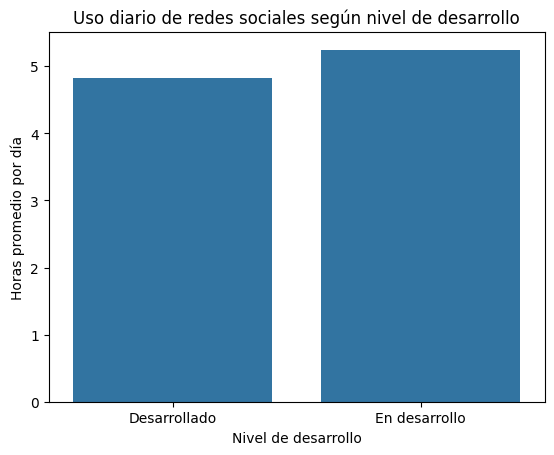

In [20]:
# Calculamos el promedio de uso diario según
# el nivel de desarrollo del país.

uso_desarrollo = (
    df.groupby("Nivel_Desarrollo")["Avg_Daily_Usage_Hours"]
      .mean()
      .reset_index()
)

sns.barplot(
    data=uso_desarrollo,
    x="Nivel_Desarrollo",
    y="Avg_Daily_Usage_Hours"
)

plt.title("Uso diario de redes sociales según nivel de desarrollo")
plt.xlabel("Nivel de desarrollo")
plt.ylabel("Horas promedio por día")
plt.show()

**Interpretación:**  
El gráfico muestra diferencias en el promedio de horas diarias de uso de redes sociales entre estudiantes de países desarrollados y en desarrollo. Los estudiantes pertenecientes a **países en desarrollo presentan un mayor promedio de uso diario**, lo que indica una mayor exposición a las redes sociales dentro de la muestra analizada.

Este resultado aporta evidencia descriptiva de una diferencia entre ambos grupos, aunque no permite afirmar que el nivel de desarrollo del país sea la causa de un mayor uso de redes sociales.

### 4.2 | Salud mental según nivel de desarrollo

En este gráfico se compara el **puntaje promedio de salud mental** entre estudiantes de países desarrollados y en desarrollo.

Dado que los valores más altos indican una mejor salud mental, la comparación permite observar si alguno de los grupos presenta indicadores de bienestar mental relativamente menos favorables.

---

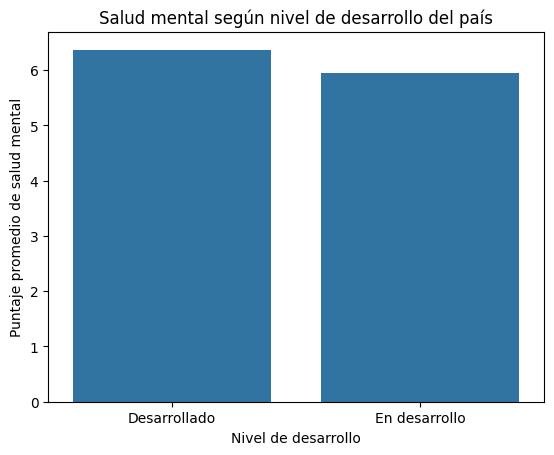

In [21]:
# Comparamos el puntaje promedio de salud mental
# entre países desarrollados y en desarrollo.

salud_desarrollo = (
    df.groupby("Nivel_Desarrollo")["Mental_Health_Score"]
      .mean()
      .reset_index()
)

sns.barplot(
    data=salud_desarrollo,
    x="Nivel_Desarrollo",
    y="Mental_Health_Score"
)

plt.title("Salud mental según nivel de desarrollo del país")
plt.xlabel("Nivel de desarrollo")
plt.ylabel("Puntaje promedio de salud mental")
plt.show()

**Interpretación:**  
Al comparar el puntaje promedio de salud mental según el nivel de desarrollo del país, se observa que los estudiantes de **países en desarrollo presentan un puntaje promedio menor** que aquellos pertenecientes a países desarrollados.

Dado que en este análisis un valor más alto de `Mental_Health_Score` representa un mejor estado de salud mental, este resultado sugiere que los estudiantes de países en desarrollo presentan un indicador de bienestar mental relativamente menos favorable dentro de la muestra. Sin embargo, esta diferencia representa una asociación descriptiva y no permite establecer una relación causal.

### 3.3 | Distribución de las horas de sueño según nivel de desarrollo

Para ampliar la comparación entre estudiantes de países desarrollados y en desarrollo, se analiza la distribución de las **horas de sueño por noche**.

Se utiliza un diagrama de caja (*boxplot*) porque permite comparar la mediana, la dispersión y la presencia de posibles valores extremos entre ambos grupos. De esta manera, se puede observar si existen diferencias en los patrones de descanso según el nivel de desarrollo del país.

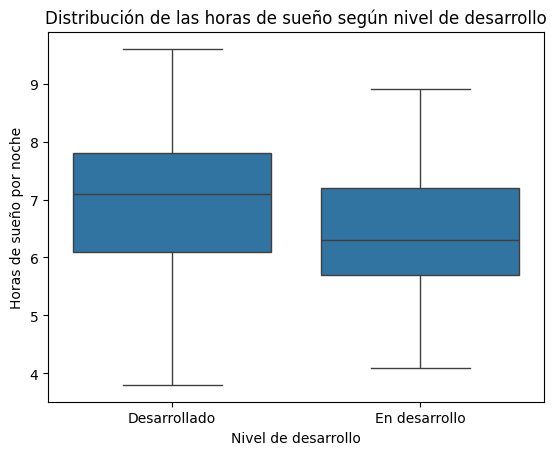

In [22]:
# Comparamos la distribución de las horas de sueño
# entre estudiantes de países desarrollados y en desarrollo.

sns.boxplot(
    data=df,
    x="Nivel_Desarrollo",
    y="Sleep_Hours_Per_Night"
)

plt.title("Distribución de las horas de sueño según nivel de desarrollo")
plt.xlabel("Nivel de desarrollo")
plt.ylabel("Horas de sueño por noche")
plt.show()

**Interpretación:**  
El boxplot permite comparar la distribución de las horas de sueño entre estudiantes de países desarrollados y en desarrollo. Las diferencias en la posición de las medianas permiten identificar qué grupo presenta, en términos generales, una menor cantidad de horas de descanso, mientras que el tamaño de las cajas permite observar la variabilidad existente dentro de cada grupo.

# 4 | Conclusión general

A partir del análisis realizado, se observan diferencias entre los estudiantes pertenecientes a **países desarrollados** y aquellos de **países en desarrollo** en varios de los indicadores vinculados al uso e impacto de las redes sociales.

En términos generales, los estudiantes de países en desarrollo presentan **un mayor promedio de horas diarias de uso de redes sociales** y, al mismo tiempo, **un puntaje promedio de salud mental más bajo**. Considerando que en este trabajo un valor mayor de `Mental_Health_Score` representa un mejor estado de salud mental, estos resultados muestran un perfil relativamente menos favorable para este grupo dentro de la muestra analizada.

Las visualizaciones realizadas permiten reforzar esta diferencia, ya que muestran de manera clara cómo se distribuyen los principales indicadores entre ambos grupos de países.

Sin embargo, estos resultados deben interpretarse con cautela. La clasificación entre países desarrollados y en desarrollo se construyó a partir del nivel de ingreso definido por el Banco Mundial, lo cual simplifica un concepto multidimensional como el desarrollo. Además, el análisis es de carácter descriptivo, por lo que permite identificar asociaciones y diferencias entre grupos, pero no establecer que el nivel de desarrollo del país sea la causa directa de los resultados observados.

En conclusión, dentro de este dataset se identifica una asociación entre el nivel de desarrollo del país y algunos indicadores relacionados con el uso de redes sociales y el bienestar de los estudiantes, siendo los resultados menos favorables, en promedio, para quienes pertenecen a países en desarrollo.